## Pytorch Neural Network Classification

### Imports

In [2]:
import torch
import pandas as pd
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

### Architecture of a classification neural network

In [88]:
# Hyperparameter
# Input Layer Shape        - number of features
# Hidden Layers            - problem specific
# Neurons per Hidden Layer - problem specific
# Output Layer Shape       - n classes, n is a integer
# Hidden Layer Activation  - usually ReLU
# Output Activation        - sigmoid or softmax
# Loss Function            - cross entropy
# Optimizer                - sgd or adam

from sklearn.datasets import make_circles

# Make 1000 samples
n_samples = 1000

# Create circles
X, y = make_circles(n_samples, noise=0.03, random_state=42)

In [89]:
import pandas as pd

circles = pd.DataFrame({"X": X[:,0], 
                        "Y": X[:,1],
                        "Label": y
                        })

circles.head(10)

,X,Y,Label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


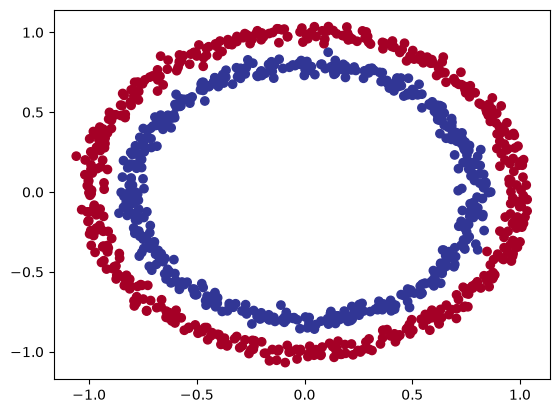

In [90]:
plt.scatter(X[:,0], X[:,1], c=y, cmap=plt.cm.RdYlBu)

#### Turn Data into Tensors

In [91]:
from sklearn.model_selection import train_test_split
device = torch.device('cuda')

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [ ]:
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
       return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))


model_0 = CircleModelV0().to(device)

# Create a loss function
loss_fn = nn.BCEWithLogitsLoss()

# Create an optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

# Accuracy function

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()

    acc = correct/len(y_pred) * 100

    return acc

## Training

In [ ]:
torch.manual_seed(42)

# Set the number of epochs
epochs = 1000

X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

for epoch in range(epochs):
    ### Training
    model_0.train()

    y_logits = model_0(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)

    acc = accuracy_fn(y_true=y_train,y_pred=y_pred)

    # Zero Gradient
    optimizer.zero_grad()

    # Backward
    loss.backward()

    # Optimizer steo
    optimizer.step()

    ### Testing
    model_0.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_logits = model_0(X_test).squeeze() 
        test_pred = torch.round(torch.sigmoid(test_logits))
        # 2. Caculate loss/accuracy
        test_loss = loss_fn(test_logits,
                            y_test)
        test_acc = accuracy_fn(y_true=y_test,
                               y_pred=test_pred)

    # Print out what's happening every 10 epochs
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")



## Multiclass Model

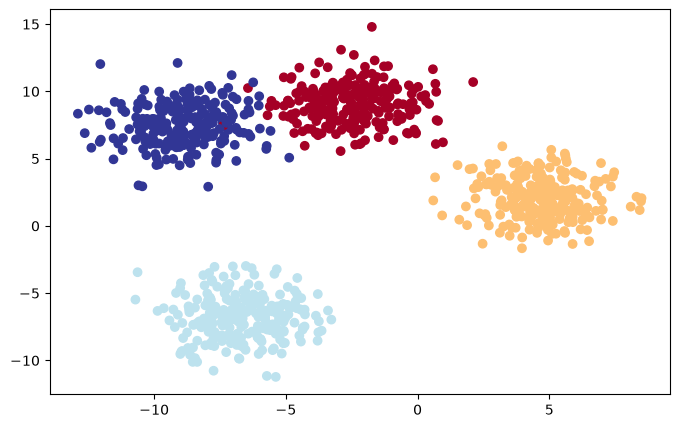

In [16]:
# Creating multi-class data
# 1. Create some multi-class data with make_blobs()
# 2. Turn the data into tensors
# 3. Split the training and test sets using train_test_split()
# 4. Visualize the data

# Settings the HyperParameters
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

X_blob, y_blob = make_blobs(n_samples=1000,
                            n_features=NUM_FEATURES,
                            centers=NUM_CLASSES,
                            cluster_std=1.5,
                            random_state=RANDOM_SEED
)

X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.float)

# Split into train and test data

X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob,
                                                                         y_blob,
                                                                         test_size=0.2,
                                                                         random_state=RANDOM_SEED
)

plt.figure(figsize=(8,5))
plt.scatter(X_blob[:,0], X_blob[:,1], c=y_blob, cmap=plt.cm.RdYlBu)



In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"

class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        super().__init__()

        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),

            nn.Linear(in_features=hidden_units, out_features=hidden_units),

            nn.Linear(in_features=hidden_units, out_features=output_features)

        )

    def forward(self,x):
        return self.linear_layer_stack(x)

model_4 = BlobModel(NUM_FEATURES, NUM_CLASSES, hidden_units=8).to(device)

In [10]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_4.parameters(),
                            lr = 0.1)

In [22]:
# Fit the model
torch.manual_seed(42)

# Set number of epochs
epochs = 100

# Put data to target device
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()

    acc = correct/len(y_pred) * 100

    return acc

for epoch in range(epochs):
    ### Training
    model_4.train()

    # 1. Forward pass
    y_logits = model_4(X_blob_train) # model outputs raw logits 
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1) # go from logits -> prediction probabilities -> prediction labels
    # print(y_logits)
    # 2. Calculate loss and accuracy
    loss = loss_fn(y_logits, y_blob_train.long()) 
    acc = accuracy_fn(y_true=y_blob_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_4.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_logits = model_4(X_blob_test)
      test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
      # 2. Calculate test loss and accuracy
      test_loss = loss_fn(test_logits, y_blob_test.long())
      test_acc = accuracy_fn(y_true=y_blob_test,
                             y_pred=test_pred)

    # Print out what's happening
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%") 

Epoch: 0 | Loss: 0.72830, Acc: 43.12% | Test Loss: 0.56297, Test Acc: 84.50%
Epoch: 10 | Loss: 0.16264, Acc: 98.88% | Test Loss: 0.14779, Test Acc: 99.00%
Epoch: 20 | Loss: 0.08976, Acc: 99.00% | Test Loss: 0.08162, Test Acc: 99.50%
Epoch: 30 | Loss: 0.06552, Acc: 99.00% | Test Loss: 0.05798, Test Acc: 99.50%
Epoch: 40 | Loss: 0.05394, Acc: 99.00% | Test Loss: 0.04630, Test Acc: 99.50%
Epoch: 50 | Loss: 0.04730, Acc: 99.00% | Test Loss: 0.03943, Test Acc: 99.50%
Epoch: 60 | Loss: 0.04304, Acc: 99.00% | Test Loss: 0.03495, Test Acc: 99.50%
Epoch: 70 | Loss: 0.04010, Acc: 99.00% | Test Loss: 0.03180, Test Acc: 99.50%
Epoch: 80 | Loss: 0.03797, Acc: 99.00% | Test Loss: 0.02948, Test Acc: 99.50%
Epoch: 90 | Loss: 0.03636, Acc: 99.00% | Test Loss: 0.02769, Test Acc: 99.50%
